# Fine-tuning Chronos on solar data (`pv_kw`)

In [1]:
# run once (locally or on Kaggle)
!pip install -q chronos-forecasting pandas matplotlib

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset
from transformers import Trainer, TrainingArguments
from chronos import ChronosPipeline

SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# picking whatever hardware is available: NVIDIA GPU (Kaggle), Apple GPU (our Macs), else CPU
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("Device:", DEVICE)

OUT_DIR = "outputs"          # tuning log, plots and saved model go here
os.makedirs(OUT_DIR, exist_ok=True)

W1120 20:18:18.352000 48863 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


## Step 1: Load the data
We load the microgrid dataset directly from huggingface. We'll use the `pv_kw` column, which is hourly solar generation.

In [3]:
URL = ("https://huggingface.co/datasets/Tristanchou/"
       "Preference-Conditioned-Heterogeneous-MARL-Microgrid/resolve/main/microgrid_opsd_multiyear.csv")

# Parse timestamp to convert it to computer-readable date-time objects
LOCAL = "data/microgrid_opsd_multiyear.csv"      # data/ is gitignored
if not os.path.exists(LOCAL):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(URL).to_csv(LOCAL, index=False)   # download once
df = pd.read_csv(LOCAL, parse_dates=["timestamp"])

print(f"The dataset shape: {df.shape}")
print( df.head())


The dataset shape: (50401, 19)
                  timestamp     pv_kw    wind_kw     load_kw  \
0 2014-12-31 23:00:00+00:00  0.202918  39.334556  186.892131   
1 2015-01-01 00:00:00+00:00  0.202918  39.334556  186.892131   
2 2015-01-01 01:00:00+00:00  0.202918  39.273729  187.654492   
3 2015-01-01 02:00:00+00:00  0.202918  39.687594  172.550697   
4 2015-01-01 03:00:00+00:00  0.202918  42.085626  164.765285   

   critical_load_kw  flexible_load_kw  price_cny_kwh  carbon_factor_kg_kwh  \
0        117.742043         69.150088       0.217932              0.713735   
1        117.742043         69.150088       0.217932              0.713735   
2        118.222330         69.432162       0.217932              0.714557   
3        108.706939         63.843758       0.217932              0.699236   
4        103.802130         60.963155       0.217932              0.685588   

   risk_level  reserve_ratio  island_flag  hour  month  dayofyear  \
0    0.551560            0.0            0    2

In [4]:
# confirm that there are no missing values
df.isnull().sum()

timestamp                     0
pv_kw                         0
wind_kw                       0
load_kw                       0
critical_load_kw              0
flexible_load_kw              0
price_cny_kwh                 0
carbon_factor_kg_kwh          0
risk_level                    0
reserve_ratio                 0
island_flag                   0
hour                          0
month                         0
dayofyear                     0
node_renewable_ratio_mean     0
node_renewable_ratio_std      0
node_deficit_pressure_mean    0
node_deficit_pressure_std     0
node_price_signal_mean        0
dtype: int64

In [5]:

pv = df.set_index("timestamp")["pv_kw"].astype("float32")

print("Gap check (should be only 1 hour):", pv.index.to_series().diff().dropna().value_counts().to_dict())

Gap check (should be only 1 hour): {Timedelta('0 days 01:00:00'): 50400}


In [6]:
# let's see what the target looks like
print(df["pv_kw"].describe())

count    50401.000000
mean        26.960887
std         38.735809
min          0.000000
25%          0.000000
50%          2.685499
75%         46.183642
max        185.131766
Name: pv_kw, dtype: float64


In [7]:
# Set timestamp as the index
pv = df.set_index("timestamp")["pv_kw"]["2016-01-01":]   # about 4.8 years
# we index out pv_kw because Chronos forecasts one stream of numbers at a time

print(pv.index.to_series().diff().value_counts().head())  # the interval should be all 1 hour

timestamp
0 days 01:00:00    41639
Name: count, dtype: int64


In [8]:
pv

timestamp
2016-01-01 00:00:00+00:00     0.012165
2016-01-01 01:00:00+00:00     0.000000
2016-01-01 02:00:00+00:00     0.000000
2016-01-01 03:00:00+00:00     0.000000
2016-01-01 04:00:00+00:00     0.000000
                               ...    
2020-09-30 19:00:00+00:00    13.720313
2020-09-30 20:00:00+00:00    13.720313
2020-09-30 21:00:00+00:00    13.720313
2020-09-30 22:00:00+00:00    13.720313
2020-09-30 23:00:00+00:00    13.720313
Name: pv_kw, Length: 41640, dtype: float64

## Step 2: Split chronologically for time-series data
The model trains on the earliest set, and we tune settings on the validation set.

In [9]:
PRED_LEN = 24                       # prediction length, forecast 24 hours ahead
VAL_DAYS, TEST_DAYS = 30, 30

series = pv.values
series   # all the hours 

array([1.2165000e-02, 0.0000000e+00, 0.0000000e+00, ..., 1.3720313e+01,
       1.3720313e+01, 1.3720313e+01], shape=(41640,))

In [10]:
# To get the row where hour for test set begins: total number of hours - (number of test days * 24 hours)

test_start = len(series) - TEST_DAYS * 24
val_start  = test_start - VAL_DAYS * 24

print(f"train: {len(series[:val_start])} hours")
print(f"validation: {len(series[val_start:test_start])} hours")
print(f"test: {len(series[test_start:])} hours")

train: 40200 hours
validation: 720 hours
test: 720 hours


## Step 3: Preparing the data with sliding window  
Here, we use the sliding window technique, a method used to process sequential data by maintaining a subset of elements (a "window") that moves through the data incrementally. 

### Why this method?
We cannot feed the entire solar data into the model at once. So the function takes a fixed-size frame (a window) and slides it across the dataset 24 hours at a time. It then stamps out lots of mini training examples.  The function sets the History (Context) and the Future (Horizon) 


- `make_windows` inputs:  
        - values: the full array of hourly PV readings.  
        - first_target and last_target: the range of positions where the answers must fall. For example, to build training windows, you'd pass the start and end of the training period.  
        - context_length: how many past hours the model sees as input.  
        - stride: how many hours to move forward between windows.


- `make_windows` cuts the pv series into pairs of (context, target).

- `tokenize_windows` coverts the pairs into tokens, and returns them in dictionary format

In [11]:
def make_windows(values, first_target, last_target, context_length, stride):
    contexts = []
    targets = []
    start = max(first_target, context_length)      # chooses the bigger value because we need enough history before the first target
    
    while start + PRED_LEN <= last_target:        #start + PRED_LEN is the value just after the last target
        contexts.append(values[start - context_length : start])     # use previous values to form the context(histroy)
        targets.append(values[start : start + PRED_LEN])            # use latter values to form the target (future/horizon)
        start = start + stride
    return np.array(contexts, dtype="float32"), np.array(targets, dtype="float32")

In [12]:
def tokenize_windows(pipe, contexts, targets):
    tokenizer = pipe.tokenizer      # pipe is the chronos pipeline we imported at the beginning
    tokenizer.config.prediction_length = PRED_LEN      # We set the tokenizer rediction length to 24hours so it knows what to expect 
    
    examples = []
    for i in range(len(contexts)):
        context = torch.tensor(contexts[i]).unsqueeze(0)     # add a batch dimension of 1 as that's what the model expects:  2D in form of (batch_size, time_steps)
        target = torch.tensor(targets[i]).unsqueeze(0)
        
        # here, we do the mean scaling (divides the values by a scale factor which is often the average size of the context values) 
        # and quantizing(binning) where it places each scaled number into one out of a fixed set of bins
        tokens, mask, scale = tokenizer.context_input_transform(context)
        labels, labels_mask = tokenizer.label_input_transform(target, scale)

#         The names that the model's forward function expects:
            # input_ids and attention_mask: the history tokens and their mask.
            # labels and decoder_attention_mask: the answer tokens and their mask.
        examples.append({
            "input_ids": tokens.squeeze(0),                  # remove the batch dimension again
            "attention_mask": mask.squeeze(0),
            "labels": labels.squeeze(0),
            "decoder_attention_mask": labels_mask.squeeze(0),
        })
    return examples

## Evaluating the model

In [13]:
# # Sets up the test data

def make_eval_data(values, eval_start, n_days, context_length):
    contexts = []
    actuals = []
    yesterdays = []
    
    for day in range(n_days):
        t = eval_start + day * PRED_LEN                      # the hour this day's forecast begins
        contexts.append(values[t - context_length : t])
        actuals.append(values[t : t + PRED_LEN])
        yesterdays.append(values[t - PRED_LEN : t])          # the 24 hours just before
        
    return (np.array(contexts, dtype="float32"),         # For each day, it returns the historical solar data before that day,
            np.array(actuals, dtype="float32"),          # the value for that day 
            np.array(yesterdays, dtype="float32"))       # 24 hours just before the forecast

Below, we compare the model against a **naive persistence baseline**
A naive persistence baseline is a simple time-series forecasting benchmark that predicts a future value will equal the most recently observed value

In [14]:
# Compares the model to a naive baseline

def get_scores(pipe, values, eval_start, n_days, context_length):
    contexts, actuals, yesterdays = make_eval_data(values, eval_start, n_days, context_length)
    pipe.model.eval()                                        # turn off dropout for forecasting
    forecasts = pipe.predict(torch.tensor(contexts), prediction_length=PRED_LEN, num_samples=20)
    forecasts = forecasts.float().cpu().numpy()              # shape: (days, 20 guesses, 24 hours)
    median = np.median(forecasts, axis=1)                    # middle of the 20 guesses
    model_mae = np.mean(np.abs(median - actuals))
    naive_mae = np.mean(np.abs(yesterdays - actuals))
    return float(model_mae), float(naive_mae)

In [15]:
# runs the fine-tuning

def train_model(pipe, train_examples, val_examples, learning_rate, epochs, batch_size,
                seed, run_name):
    args = TrainingArguments(
        output_dir=os.path.join(OUT_DIR, "trainer_tmp"),
        learning_rate=learning_rate,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        logging_steps=50,
        eval_strategy="epoch",              # check the validation loss after every epoch
        save_strategy="no",
        seed=seed,
        report_to="none",                   # W&B sign-ups were paused, so we log to CSV instead (see grid search)
        dataloader_pin_memory=False,        # avoids a warning on Mac
        run_name=run_name,
    )
    trainer = Trainer(model=pipe.model.model, args=args,
                      train_dataset=train_examples, eval_dataset=val_examples)
    trainer.train()                         # updates the model inside pipe, in place
    return trainer

In [16]:
def run_experiment(model_name="amazon/chronos-t5-mini", context_length=168, learning_rate=1e-4,
                   epochs=1, batch_size=16, stride=6, seed=42,
                   final_test=False, save_dir=None, run_name=None, keep_pipe=False):
    set_seed(seed)
    results = {}

    pipe = ChronosPipeline.from_pretrained(model_name, device_map=DEVICE, torch_dtype=torch.float32)  # 1

    val_model, val_naive = get_scores(pipe, series, val_start, VAL_DAYS, context_length)   # 2. BEFORE
    results["val_mae_zero_shot"] = val_model
    results["val_mae_naive"] = val_naive
    if final_test:
        test_model, test_naive = get_scores(pipe, series, test_start, TEST_DAYS, context_length)
        results["test_mae_zero_shot"] = test_model
        results["test_mae_naive"] = test_naive

    train_x, train_y = make_windows(series, 0, val_start, context_length, stride)          # 3. prepare
    val_x, val_y = make_windows(series, val_start, test_start, context_length, PRED_LEN)
    train_examples = tokenize_windows(pipe, train_x, train_y)
    val_examples = tokenize_windows(pipe, val_x, val_y)
    results["n_train_windows"] = len(train_examples)

    start_time = time.time()                                                               # 4. train
    trainer = train_model(pipe, train_examples, val_examples, learning_rate, epochs,
                          batch_size, seed, run_name)
    results["train_minutes"] = round((time.time() - start_time) / 60, 1)

    val_model, _ = get_scores(pipe, series, val_start, VAL_DAYS, context_length)           # 5. AFTER
    results["val_mae_finetuned"] = val_model
    if final_test:
        test_model, _ = get_scores(pipe, series, test_start, TEST_DAYS, context_length)
        results["test_mae_finetuned"] = test_model

    if save_dir is not None:                                                               # 6. wrap up
        trainer.save_model(save_dir)
    if keep_pipe:                                     # used for the final plots
        return results, pipe
    del pipe, trainer
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return results

In [17]:
res = run_experiment()
for k, v in res.items():
    print(f"{k:22s} {v}")

config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 81.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/89 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Epoch,Training Loss,Validation Loss
1,2.207545,2.180892


val_mae_zero_shot      5.650966167449951
val_mae_naive          6.334142208099365
n_train_windows        6669
train_minutes          5.1
val_mae_finetuned      5.922456741333008


In [18]:
# Grid search with a CSV log

import csv, os

def log_result(settings, results, path=os.path.join(OUT_DIR, "tuning_log.csv")):
    row = dict(settings)
    row.update(results)
    new_file = not os.path.exists(path)
    with open(path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row.keys()))
        if new_file:
            writer.writeheader()              # write the column names once
        writer.writerow(row)

# the full grid (4 learning rates x 3 epochs = 12 runs) is too slow on a laptop, so we try 3 learning rates for 1 epoch
learning_rates = [1e-5, 1e-4, 1e-3]
epoch_options = [1]

for lr in learning_rates:
    for ep in epoch_options:
        settings = {"learning_rate": lr, "epochs": ep}
        results = run_experiment(learning_rate=lr, epochs=ep)
        log_result(settings, results)
        print(settings, "->", round(results["val_mae_finetuned"], 3))

Loading weights:   0%|          | 0/89 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.674549,2.467669


{'learning_rate': 1e-05, 'epochs': 1} -> 5.911


Loading weights:   0%|          | 0/89 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.207507,2.180932


{'learning_rate': 0.0001, 'epochs': 1} -> 5.906


Loading weights:   0%|          | 0/89 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.142895,2.189189


{'learning_rate': 0.001, 'epochs': 1} -> 5.792


## Tracking our runs
We wanted to track runs with Weights & Biases (Lectures 8 & 9), but W&B had paused new sign-ups when we tried, so we couldn't create accounts. Instead, `log_result` adds a row to `outputs/tuning_log.csv` after every run: the settings plus the scores. It's the same idea with less tooling.

In [19]:
log = pd.read_csv(os.path.join(OUT_DIR, "tuning_log.csv"))
log.sort_values("val_mae_finetuned")

,learning_rate,epochs,val_mae_zero_shot,val_mae_naive,n_train_windows,train_minutes,val_mae_finetuned
2,0.00100,1,5.650966,6.334142,6669,5.9,5.791772
1,0.00010,1,5.650966,6.334142,6669,5.0,5.905601
0,0.00001,1,5.650966,6.334142,6669,5.5,5.911122


## Final test
We pick the learning rate with the lowest **validation** error, then score it on the **test** month once. We never used the test month to choose anything, so this number is a fair estimate.

In [20]:
best_lr = float(log.sort_values("val_mae_finetuned").iloc[0]["learning_rate"])
print("best learning rate on validation:", best_lr)

final, best_pipe = run_experiment(learning_rate=best_lr, epochs=1, final_test=True, keep_pipe=True,
                                  save_dir=os.path.join(OUT_DIR, "chronos-mini-solar"))

print(f"naive (same as yesterday): {final['test_mae_naive']:.3f} kW")
print(f"chronos zero-shot        : {final['test_mae_zero_shot']:.3f} kW")
print(f"chronos fine-tuned       : {final['test_mae_finetuned']:.3f} kW")
change = (final['test_mae_finetuned'] - final['test_mae_zero_shot']) / final['test_mae_zero_shot'] * 100
print(f"fine-tuning changed the error by {change:+.1f}% vs zero-shot")

best learning rate on validation: 0.001


Loading weights:   0%|          | 0/89 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.143336,2.188327


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

naive (same as yesterday): 6.251 kW
chronos zero-shot        : 5.861 kW
chronos fine-tuned       : 5.806 kW
fine-tuning changed the error by -0.9% vs zero-shot


## What the forecasts look like
Black is what actually happened, and orange is the fine-tuned forecast. The shaded band covers the middle 80% of the model's 20 guesses, so a wider band means the model is less sure.

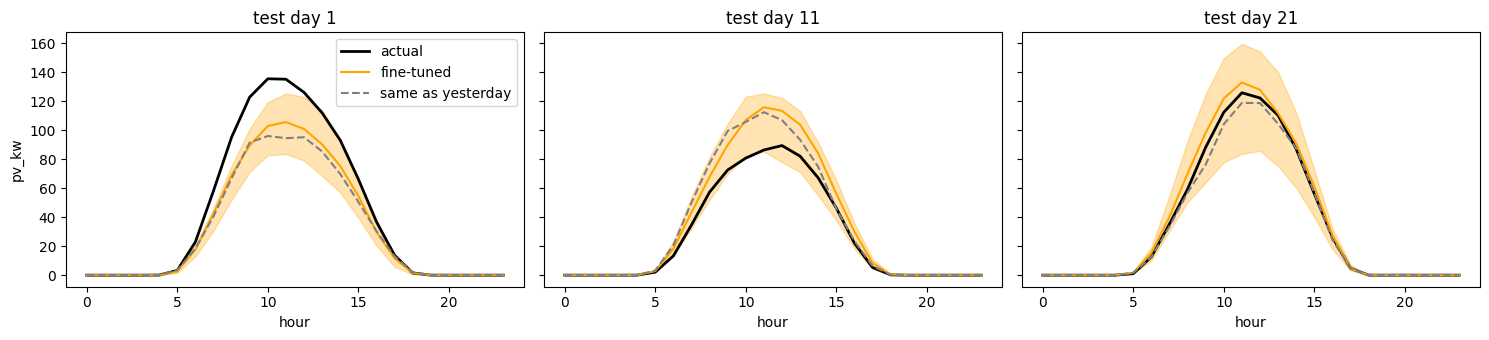

In [21]:
contexts, actuals, yesterdays = make_eval_data(series, test_start, TEST_DAYS, 168)
best_pipe.model.eval()
fc = best_pipe.predict(torch.tensor(contexts), prediction_length=PRED_LEN, num_samples=20).float().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, d in zip(axes, [0, 10, 20]):
    lo, med, hi = np.quantile(fc[d], [0.1, 0.5, 0.9], axis=0)
    ax.fill_between(range(PRED_LEN), lo, hi, color="orange", alpha=0.3)
    ax.plot(actuals[d], "k", lw=2, label="actual")
    ax.plot(med, color="orange", label="fine-tuned")
    ax.plot(yesterdays[d], "--", color="grey", label="same as yesterday")
    ax.set_title(f"test day {d + 1}"); ax.set_xlabel("hour")
axes[0].set_ylabel("pv_kw"); axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "test_forecasts.png"), dpi=150); plt.show()